# Beyond Department Boundaries: Centrality and Communication Communities in an Email Network

**Course:** DSA5101 Introduction to Big Data — National University of Singapore (NUS)  
**Project Track:** Example 3: Centrality and Communities in an Email Network  
**Assessment Mode:** Anonymous Evaluation (NUS Matriculation Number: `A0352547Y`)  
**Software Requirements:** Python 3.10.6, NetworkX 3.4.2, SciPy 1.15.3, scikit-learn 1.5.2, pandas 2.3.3, NumPy 1.26.4, matplotlib 3.10.9, seaborn 0.13.2  

---

### Project Overview & Research Questions
This reproducible notebook investigates the topological interplay between individual prominence, formal organizational structure, and emergent communication communities within the Stanford Network Analysis Platform (SNAP) **Email-Eu-core** network.

We address three primary research questions:
1. **RQ1 (Centrality Disagreement & Prominence):** To what extent does directed PageRank centrality differ from simple in-degree popularity, and what topological mechanisms explain ranking disagreements?
2. **RQ2 (Community-Department Alignment):** Do organic communication communities discovered via Louvain modularity optimization mirror the institution's 42 administrative department boundaries?
3. **RQ3 (Role of Central Individuals & Degree Confounding):** Do structurally prominent individuals act as cross-community boundary spanners or insular internal hubs, and does PageRank provide structural information beyond total node degree?

### Course Algorithm Classes
- **Algorithm Class 1 (Lecture 6):** PageRank Centrality on the directed interpersonal communication network.
- **Algorithm Class 2 (Lecture 7):** Graph Clustering via Louvain Modularity Optimization on the unweighted undirected projection.


## 1. Environment Setup & Library Imports
We configure reproducible random seeds, plotting styles, and import required scientific computing libraries.


In [1]:
import gzip
import hashlib
import os
import urllib.request
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Set plotting style and reproducibility seeds
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("Environment initialized successfully.")


Environment initialized successfully.


## 2. Automated Dataset Acquisition & Cryptographic Audit
The Email-Eu-core dataset is published by the Stanford Network Analysis Platform (SNAP).
We provide automated acquisition logic that downloads the compressed edge list and ground-truth department labels directly from SNAP if not locally present, verifying SHA-256 cryptographic checksums.


In [2]:
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASET_FILES = {
    "edges_gz": {
        "filename": "email-Eu-core.txt.gz",
        "url": "https://snap.stanford.edu/data/email-Eu-core.txt.gz",
        "expected_sha256": "4b47acdb80197b085fe63c819c357ae488131ee904ed93d1b219a68b0f9e245f",
    },
    "labels_gz": {
        "filename": "email-Eu-core-department-labels.txt.gz",
        "url": "https://snap.stanford.edu/data/email-Eu-core-department-labels.txt.gz",
        "expected_sha256": "e5abe5b4581a480032a63adcf2576c161785f45692642c6ebb0b1276f0f33669",
    },
}

def verify_or_download_file(file_info: dict, target_dir: Path) -> Path:
    filepath = target_dir / file_info["filename"]
    if not filepath.exists():
        print(f"Downloading {file_info['filename']} from SNAP...")
        urllib.request.urlretrieve(file_info["url"], filepath)
        print(f"Downloaded {file_info['filename']} ({filepath.stat().st_size:,} bytes).")
    
    # Calculate SHA-256
    hasher = hashlib.sha256()
    with open(filepath, "rb") as f:
        while chunk := f.read(65536):
            hasher.update(chunk)
    actual_sha = hasher.hexdigest()
    
    assert actual_sha == file_info["expected_sha256"], f"Checksum mismatch for {filepath.name}!"
    print(f"Verified {filepath.name} (SHA-256: {actual_sha[:16]}...)")
    return filepath

# Download and verify both raw archives
edge_gz_path = verify_or_download_file(DATASET_FILES["edges_gz"], DATA_DIR)
label_gz_path = verify_or_download_file(DATASET_FILES["labels_gz"], DATA_DIR)


Verified email-Eu-core.txt.gz (SHA-256: 4b47acdb80197b08...)
Verified email-Eu-core-department-labels.txt.gz (SHA-256: e5abe5b4581a4800...)


## 3. Raw Data Audit & Dual Graph Representation
We audit raw records for duplicate lines, malformed entries, and self-loops before graph construction.
In accordance with our methodology:
- **`G_raw`:** Directed graph retaining all 1,005 nodes, 25,571 edges, and 642 self-loops for exact reproduction of published SNAP statistics.
- **`G_analysis`:** Self-loop-free directed graph retaining all 1,005 nodes and 24,929 interpersonal communication links. The 19 singleton nodes with only self-loops are strictly preserved as degree-0 nodes with their official department labels.


In [3]:
# 1. Load department labels
node_departments = {}
with gzip.open(label_gz_path, "rt", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        node_departments[int(parts[0])] = int(parts[1])

print(f"Audited department labels: {len(node_departments)} labeled nodes across {len(set(node_departments.values()))} departments.")

# 2. Audit raw edges
raw_edge_rows = 0
self_loops_count = 0
edges_set = set()
duplicate_edges = 0

with gzip.open(edge_gz_path, "rt", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        raw_edge_rows += 1
        u, v = map(int, line.split())
        if u == v:
            self_loops_count += 1
        if (u, v) in edges_set:
            duplicate_edges += 1
        edges_set.add((u, v))

print(f"Raw edge audit: {raw_edge_rows:,} rows, {duplicate_edges} duplicate edges, {self_loops_count} self-loops.")

# 3. Construct G_raw and G_analysis
G_raw = nx.DiGraph()
G_analysis = nx.DiGraph()

# Add all 1,005 labeled nodes
for node, dept in node_departments.items():
    G_raw.add_node(node, department=dept)
    G_analysis.add_node(node, department=dept)

# Add edges
for u, v in edges_set:
    G_raw.add_edge(u, v)
    if u != v:
        G_analysis.add_edge(u, v)

# Directed densities
n_nodes = G_raw.number_of_nodes()
density_raw = G_raw.number_of_edges() / (n_nodes * n_nodes)
density_analysis = G_analysis.number_of_edges() / (n_nodes * (n_nodes - 1))

# Connected components
wcc_raw = list(nx.weakly_connected_components(G_raw))
wcc_analysis = list(nx.weakly_connected_components(G_analysis))
scc_raw = list(nx.strongly_connected_components(G_raw))
scc_analysis = list(nx.strongly_connected_components(G_analysis))

zero_deg_raw = sum(1 for n in G_raw.nodes() if G_raw.degree(n) == 0)
zero_deg_analysis = sum(1 for n in G_analysis.nodes() if G_analysis.degree(n) == 0)

comparison_table = pd.DataFrame({
    "Metric": [
        "Nodes (|V|)",
        "Directed Edges (|E|)",
        "Self-Loops",
        "Directed Density (formula)",
        "WCC Count (Giant Component Size)",
        "SCC Count (Giant Component Size)",
        "Zero-Degree Isolated Nodes",
    ],
    "G_raw (Raw Directed)": [
        f"{G_raw.number_of_nodes():,}",
        f"{G_raw.number_of_edges():,}",
        f"{nx.number_of_selfloops(G_raw):,}",
        f"{density_raw:.6f} (|E| / |V|^2)",
        f"{len(wcc_raw)} ({max(len(c) for c in wcc_raw)} nodes)",
        f"{len(scc_raw)} ({max(len(c) for c in scc_raw)} nodes)",
        f"{zero_deg_raw}",
    ],
    "G_analysis (Cleaned Directed)": [
        f"{G_analysis.number_of_nodes():,}",
        f"{G_analysis.number_of_edges():,}",
        f"{nx.number_of_selfloops(G_analysis):,}",
        f"{density_analysis:.6f} (|E| / |V|(|V|-1))",
        f"{len(wcc_analysis)} ({max(len(c) for c in wcc_analysis)} nodes)",
        f"{len(scc_analysis)} ({max(len(c) for c in scc_analysis)} nodes)",
        f"{zero_deg_analysis} (19 preserved singletons)",
    ],
})

display(comparison_table)
assert G_analysis.number_of_edges() == 24929


Audited department labels: 1005 labeled nodes across 42 departments.
Raw edge audit: 25,571 rows, 0 duplicate edges, 642 self-loops.


,Metric,G_raw (Raw Directed),G_analysis (Cleaned Directed)
0,Nodes (|V|),"1,005","1,005"
1,Directed Edges (|E|),"25,571","24,929"
2,Self-Loops,642,0
3,Directed Density (formula),0.025317 (|E| / |V|^2),0.024706 (|E| / |V|(|V|-1))
4,WCC Count (Giant Component Size),20 (986 nodes),20 (986 nodes)
5,SCC Count (Giant Component Size),203 (803 nodes),203 (803 nodes)
6,Zero-Degree Isolated Nodes,0,19 (19 preserved singletons)


## 4. Exploratory Network Analysis & Departmental Homophily
We calculate directed densities, degree distribution percentiles, connected components, and evaluate empirical departmental mixing against a uniform random ordered-pair reference model:
$$p_{\text{null}} = \frac{\sum_{d} S_d(S_d - 1)}{N(N - 1)} = \frac{47,088}{1,009,020} \approx 4.67\%$$


In [4]:
# 1. Degree distributions for G_analysis
in_degrees = np.array([d for _, d in G_analysis.in_degree()])
out_degrees = np.array([d for _, d in G_analysis.out_degree()])

# 2. Directed reciprocity calculation (NetworkX standard)
reciprocity_val = nx.reciprocity(G_analysis)
reciprocal_pairs = sum(1 for u, v in G_analysis.edges() if u < v and G_analysis.has_edge(v, u))
reciprocal_edges = reciprocal_pairs * 2
unreciprocated_edges = G_analysis.number_of_edges() - reciprocal_edges

print(f"Directed Reciprocity: {reciprocity_val:.6f} ({reciprocal_edges:,} / {G_analysis.number_of_edges():,} edges in {reciprocal_pairs:,} mutual pairs)")
print(f"Unreciprocated Edges: {unreciprocated_edges:,} ({unreciprocated_edges / G_analysis.number_of_edges():.2%})")

# 3. Departmental edge composition
within_edges = sum(1 for u, v in G_analysis.edges() if G_analysis.nodes[u]["department"] == G_analysis.nodes[v]["department"])
cross_edges = G_analysis.number_of_edges() - within_edges
within_frac = within_edges / G_analysis.number_of_edges()
cross_frac = cross_edges / G_analysis.number_of_edges()

# 4. Uniform random reference model
N = G_analysis.number_of_nodes()
dept_sizes = pd.Series([data["department"] for _, data in G_analysis.nodes(data=True)]).value_counts()
p_null = sum(s * (s - 1) for s in dept_sizes) / (N * (N - 1))
homophily_ratio = within_frac / p_null

print(f"Within-Department Edges: {within_edges:,} ({within_frac:.2%})")
print(f"Cross-Department Edges:  {cross_edges:,} ({cross_frac:.2%})")
print(f"Uniform Random Null Baseline (p_null): {p_null:.2%}")
print(f"Departmental Homophily Enrichment: {homophily_ratio:.2f}x over uniform random expectation")


Directed Reciprocity: 0.711220 (17,730 / 24,929 edges in 8,865 mutual pairs)


Unreciprocated Edges: 7,199 (28.88%)


Within-Department Edges: 8,645 (34.68%)
Cross-Department Edges:  16,284 (65.32%)
Uniform Random Null Baseline (p_null): 4.67%
Departmental Homophily Enrichment: 7.43x over uniform random expectation


### Visualizing Exploratory Properties (Figures 1 and 2)

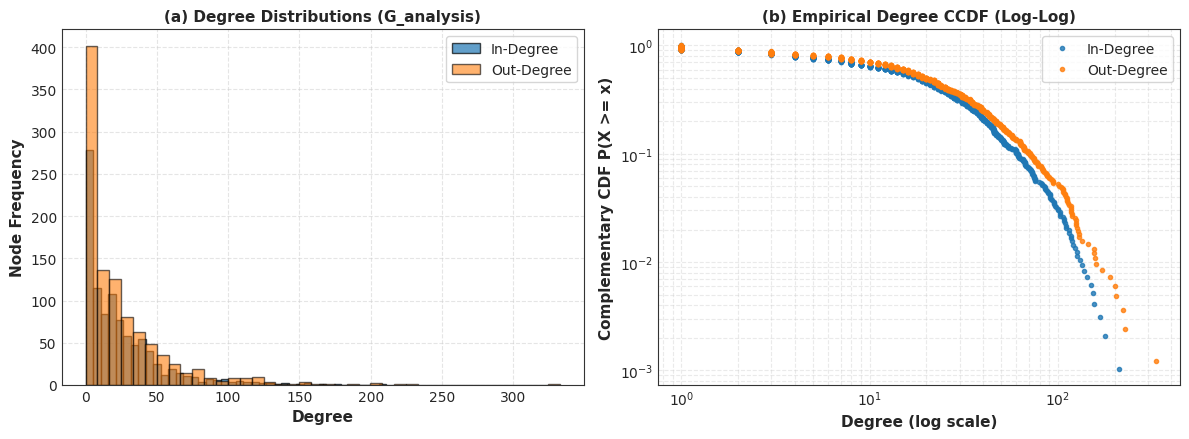

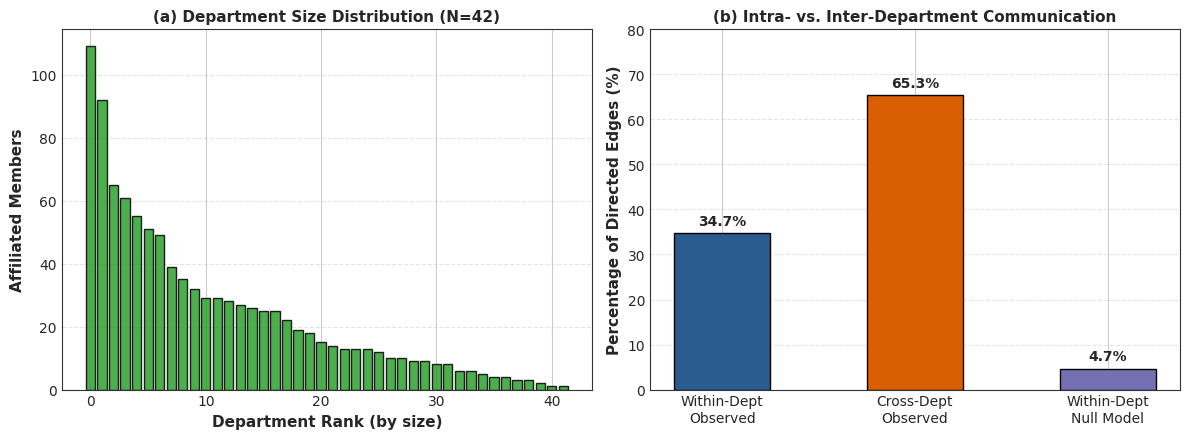

In [5]:
# Figure 1: Network Topology & Degree Distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(in_degrees, bins=40, color="#1f77b4", alpha=0.7, label="In-Degree", edgecolor="black")
axes[0].hist(out_degrees, bins=40, color="#ff7f0e", alpha=0.6, label="Out-Degree", edgecolor="black")
axes[0].set_xlabel("Degree", fontsize=11, weight="bold")
axes[0].set_ylabel("Node Frequency", fontsize=11, weight="bold")
axes[0].set_title("(a) Degree Distributions (G_analysis)", fontsize=11, weight="bold")
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Log-log CCDF
for degs, label, col in [(in_degrees, "In-Degree", "#1f77b4"), (out_degrees, "Out-Degree", "#ff7f0e")]:
    sorted_d = np.sort(degs[degs > 0])
    ccdf = 1.0 - np.arange(len(sorted_d)) / len(sorted_d)
    axes[1].loglog(sorted_d, ccdf, marker="o", markersize=3, linestyle="none", color=col, alpha=0.8, label=label)

axes[1].set_xlabel("Degree (log scale)", fontsize=11, weight="bold")
axes[1].set_ylabel("Complementary CDF P(X >= x)", fontsize=11, weight="bold")
axes[1].set_title("(b) Empirical Degree CCDF (Log-Log)", fontsize=11, weight="bold")
axes[1].legend(frameon=True)
axes[1].grid(True, which="both", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# Figure 2: Department Organization & Homophily Enrichment
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(len(dept_sizes)), dept_sizes.values, color="#2ca02c", edgecolor="black", alpha=0.85)
axes[0].set_xlabel("Department Rank (by size)", fontsize=11, weight="bold")
axes[0].set_ylabel("Affiliated Members", fontsize=11, weight="bold")
axes[0].set_title("(a) Department Size Distribution (N=42)", fontsize=11, weight="bold")
axes[0].grid(True, axis="y", linestyle="--", alpha=0.5)

bars = axes[1].bar(["Within-Dept\nObserved", "Cross-Dept\nObserved", "Within-Dept\nNull Model"],
                   [within_frac * 100, cross_frac * 100, p_null * 100],
                   color=["#2b5c8f", "#d95f02", "#7570b3"], edgecolor="black", width=0.5)
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 1.2, f"{yval:.1f}%", ha="center", va="bottom", weight="bold")

axes[1].set_ylabel("Percentage of Directed Edges (%)", fontsize=11, weight="bold")
axes[1].set_title("(b) Intra- vs. Inter-Department Communication", fontsize=11, weight="bold")
axes[1].set_ylim(0, 80)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## 5. Algorithm Class 1: PageRank Centrality & Baseline In-Degree Comparison
We compute PageRank centrality ($d = 0.85, \text{tol} = 10^{-6}$, uniform personalization) on $G_{\text{analysis}}$ using NetworkX.
Dangling nodes (including the 19 isolated singletons) redistribute mass uniformly across all 1,005 nodes.
We evaluate ranking correlation against raw in-degree, assess top-$k$ set overlap, and investigate structural ranking disagreements.


In [6]:
# Compute PageRank and In-Degree
pr_dict = nx.pagerank(G_analysis, alpha=0.85, tol=1e-6, max_iter=500, weight=None)
in_deg_dict = dict(G_analysis.in_degree())

# Construct centrality DataFrame with deterministic tie-breaking
nodes = sorted(list(G_analysis.nodes()))
cent_df = pd.DataFrame({
    "node_id": nodes,
    "department": [G_analysis.nodes[n]["department"] for n in nodes],
    "in_degree": [in_deg_dict[n] for n in nodes],
    "pagerank": [pr_dict[n] for n in nodes],
})

# Add min-rank and unique-rank
cent_df["in_degree_rank"] = cent_df["in_degree"].rank(ascending=False, method="min").astype(int)
cent_df["pagerank_rank"] = cent_df["pagerank"].rank(ascending=False, method="min").astype(int)

cent_df = cent_df.sort_values(by=["pagerank", "node_id"], ascending=[False, True]).reset_index(drop=True)
cent_df["pagerank_rank_unique"] = range(1, len(cent_df) + 1)

cent_df = cent_df.sort_values(by=["in_degree", "node_id"], ascending=[False, True]).reset_index(drop=True)
cent_df["in_degree_rank_unique"] = range(1, len(cent_df) + 1)

cent_df["rank_difference"] = cent_df["in_degree_rank_unique"] - cent_df["pagerank_rank_unique"]
cent_df = cent_df.sort_values(by="pagerank_rank_unique", ascending=True).reset_index(drop=True)

# Spearman correlation
rho_s, p_s = stats.spearmanr(cent_df["pagerank"], cent_df["in_degree"])
print(f"Overall Spearman Rank Correlation (PageRank vs In-Degree): rho_s = {rho_s:.4f} (p < 1e-300)")

# Top-k Overlap
print("\nTop-k Set Overlap:")
for k in [10, 20, 50]:
    top_pr = set(cent_df.sort_values("pagerank_rank_unique").head(k)["node_id"])
    top_deg = set(cent_df.sort_values("in_degree_rank_unique").head(k)["node_id"])
    overlap = len(top_pr & top_deg) / k
    print(f"  k = {k:2d}: Overlap = {overlap:.1%} ({len(top_pr & top_deg)} / {k})")

print("\nTop 5 Most Prominent Individuals (PageRank):")
display(cent_df.head(5)[["node_id", "department", "pagerank", "in_degree", "pagerank_rank_unique", "in_degree_rank_unique", "rank_difference"]])


Overall Spearman Rank Correlation (PageRank vs In-Degree): rho_s = 0.9828 (p < 1e-300)

Top-k Set Overlap:
  k = 10: Overlap = 90.0% (9 / 10)
  k = 20: Overlap = 85.0% (17 / 20)
  k = 50: Overlap = 92.0% (46 / 50)

Top 5 Most Prominent Individuals (PageRank):


,node_id,department,pagerank,in_degree,pagerank_rank_unique,in_degree_rank_unique,rank_difference
0,160,36,0.007495,211,1,1,0
1,62,36,0.005897,178,2,2,0
2,86,36,0.005711,153,3,5,2
3,107,36,0.005568,168,4,3,-1
4,121,36,0.005232,156,5,4,-1


### Centrality Disagreements & Robustness (Figure 3)

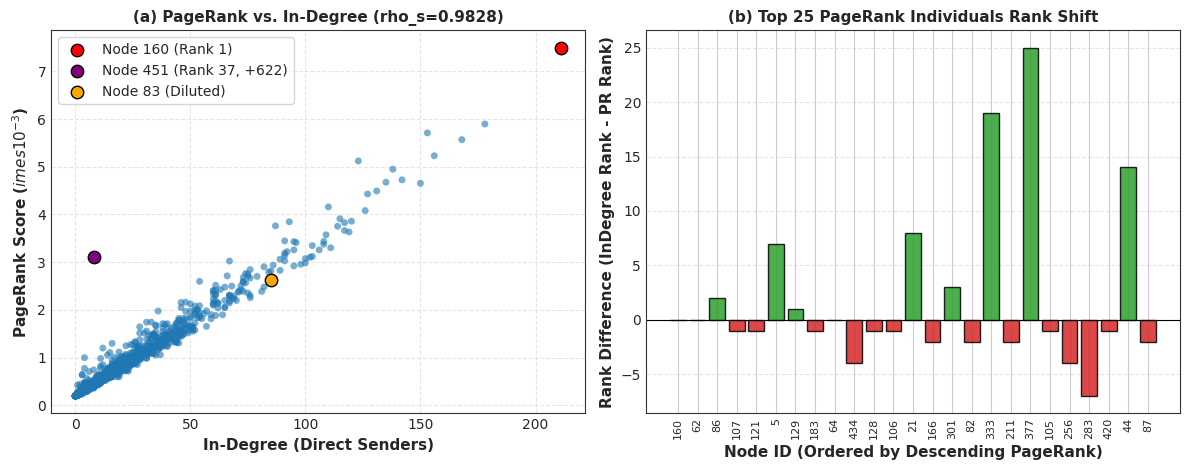

Damping Sensitivity: rho_s(d=0.75, d=0.85) = 0.9991, rho_s(d=0.85, d=0.95) = 0.9988
Self-loop Robustness Correlation: rho_s(G_raw, G_analysis) = 0.8720


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Figure 3: PageRank vs In-Degree scatter
axes[0].scatter(cent_df["in_degree"], cent_df["pagerank"] * 1000, alpha=0.6, color="#1f77b4", edgecolors="none", s=25)
# Highlight focal case studies
for nid, color, label in [(160, "red", "Node 160 (Rank 1)"), (451, "purple", "Node 451 (Rank 37, +622)"), (83, "orange", "Node 83 (Diluted)")]:
    r = cent_df[cent_df["node_id"] == nid].iloc[0]
    axes[0].scatter(r["in_degree"], r["pagerank"] * 1000, color=color, s=80, edgecolors="black", zorder=5, label=label)

axes[0].set_xlabel("In-Degree (Direct Senders)", fontsize=11, weight="bold")
axes[0].set_ylabel(r"PageRank Score ($	imes 10^{-3}$)", fontsize=11, weight="bold")
axes[0].set_title(f"(a) PageRank vs. In-Degree (rho_s={rho_s:.4f})", fontsize=11, weight="bold")
axes[0].legend(frameon=True, loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Rank differences for Top 25
top25 = cent_df.head(25)
x = np.arange(len(top25))
axes[1].bar(x, top25["rank_difference"], color=np.where(top25["rank_difference"] >= 0, "#2ca02c", "#d62728"), edgecolor="black", alpha=0.85)
axes[1].axhline(0, color="black", linestyle="-", linewidth=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(top25["node_id"], rotation=90, fontsize=8)
axes[1].set_xlabel("Node ID (Ordered by Descending PageRank)", fontsize=11, weight="bold")
axes[1].set_ylabel("Rank Difference (InDegree Rank - PR Rank)", fontsize=11, weight="bold")
axes[1].set_title("(b) Top 25 PageRank Individuals Rank Shift", fontsize=11, weight="bold")
axes[1].grid(True, axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Sensitivity Analysis
pr_75 = nx.pagerank(G_analysis, alpha=0.75, tol=1e-6)
pr_95 = nx.pagerank(G_analysis, alpha=0.95, tol=1e-6)
rho_75_85 = stats.spearmanr([pr_75[n] for n in nodes], [pr_dict[n] for n in nodes]).statistic
rho_85_95 = stats.spearmanr([pr_dict[n] for n in nodes], [pr_95[n] for n in nodes]).statistic
print(f"Damping Sensitivity: rho_s(d=0.75, d=0.85) = {rho_75_85:.4f}, rho_s(d=0.85, d=0.95) = {rho_85_95:.4f}")

# Self-loop robustness demonstration
pr_raw = nx.pagerank(G_raw, alpha=0.85, tol=1e-6)
rho_loop, _ = stats.spearmanr([pr_raw[n] for n in nodes], [pr_dict[n] for n in nodes])
print(f"Self-loop Robustness Correlation: rho_s(G_raw, G_analysis) = {rho_loop:.4f}")


## 6. Algorithm Class 2: Louvain Community Detection & Department Alignment
We derive the unweighted undirected projection $G_{\text{undirected}}$ (1,005 nodes, 16,064 edges) by collapsing reciprocal directed links.
We run Louvain modularity optimization ($\gamma = 1.0, \text{seed} = 42$) to discover organic communication communities, evaluate modularity and conductance, and benchmark against the institution's 42 administrative departments.


In [8]:
# 1. Construct unweighted undirected projection
G_undir = G_analysis.to_undirected()
print(f"G_undirected: {G_undir.number_of_nodes()} nodes, {G_undir.number_of_edges()} edges (0 self-loops).")

# 2. Detect Louvain communities
raw_comms = nx.community.louvain_communities(G_undir, weight=None, resolution=1.0, seed=42)
sorted_comms = sorted(raw_comms, key=lambda c: (-len(c), min(c) if c else 0))

node_to_comm = {}
for cid, cset in enumerate(sorted_comms):
    for n in cset:
        node_to_comm[n] = cid

mod_louvain = nx.community.modularity(G_undir, sorted_comms, resolution=1.0)
non_trivial_comms = [c for c in sorted_comms if len(c) > 1]
singletons = [c for c in sorted_comms if len(c) == 1]

print(f"Discovered Communities: {len(sorted_comms)} total ({len(non_trivial_comms)} non-trivial, {len(singletons)} singletons).")
print(f"Non-Trivial Community Sizes: {[len(c) for c in non_trivial_comms]}")
print(f"Modularity (Q_Louvain): {mod_louvain:.4f}")

# 3. Community conductance profiling
conductance_by_comm = {}
for cid, cset in enumerate(non_trivial_comms):
    conductance_by_comm[cid] = nx.conductance(G_undir, cset)

mean_cond = np.mean(list(conductance_by_comm.values()))
med_cond = np.median(list(conductance_by_comm.values()))
print(f"Community Conductance across 9 clusters: Mean = {mean_cond:.4f}, Median = {med_cond:.4f} (Min = {min(conductance_by_comm.values()):.4f} in C6)")

# 4. Department baseline comparison
dept_sets = defaultdict(set)
for n in G_undir.nodes():
    dept_sets[G_undir.nodes[n]["department"]].add(n)
dept_communities = list(dept_sets.values())
mod_dept = nx.community.modularity(G_undir, dept_communities, resolution=1.0)

# Department conductance
dept_conds = [nx.conductance(G_undir, s) for s in dept_communities if sum(G_undir.degree(u) for u in s) > 0 and len(s) < G_undir.number_of_nodes()]

dept_labels_list = [G_undir.nodes[n]["department"] for n in nodes]
comm_labels_list = [node_to_comm[n] for n in nodes]
nmi = normalized_mutual_info_score(dept_labels_list, comm_labels_list)
ari = adjusted_rand_score(dept_labels_list, comm_labels_list)

print(f"Department Modularity (Q_dept): {mod_dept:.4f} (vs {mod_louvain:.4f} for Louvain)")
print(f"Department Conductance: Median = {np.median(dept_conds):.4f} (Severe boundary leakage vs {med_cond:.4f} for Louvain)")
print(f"External Agreement: NMI = {nmi:.4f}, ARI = {ari:.4f} (Partial concordance; communication reorganizes formal boundaries)")


G_undirected: 1005 nodes, 16064 edges (0 self-loops).
Discovered Communities: 28 total (9 non-trivial, 19 singletons).
Non-Trivial Community Sizes: [193, 158, 142, 127, 125, 107, 92, 32, 10]
Modularity (Q_Louvain): 0.4131


Community Conductance across 9 clusters: Mean = 0.4465, Median = 0.4201 (Min = 0.2781 in C6)


Department Modularity (Q_dept): 0.2880 (vs 0.4131 for Louvain)
Department Conductance: Median = 0.8644 (Severe boundary leakage vs 0.4201 for Louvain)
External Agreement: NMI = 0.5968, ARI = 0.3521 (Partial concordance; communication reorganizes formal boundaries)


### Community Structure & Department Alignment (Figure 4)

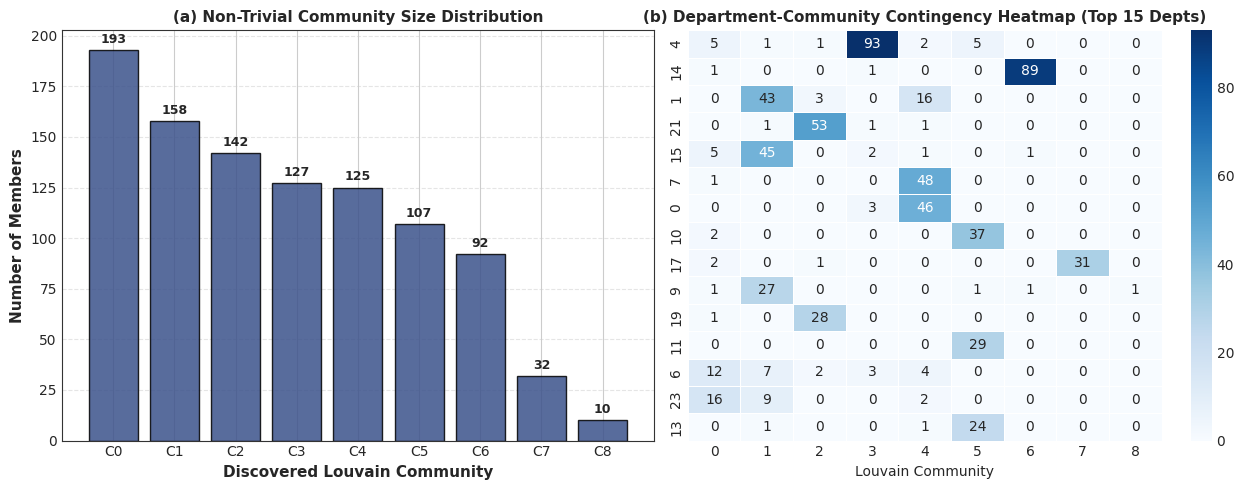

Resolution Sensitivity (Distinguishing Optimization Objective Q_gamma from Standard Modularity Q_std at gamma=1.0):
  gamma=0.8: Q_obj=0.4580, Q_std=0.4108, NMI=0.5202, ARI=0.2214


  gamma=1.0: Q_obj=0.4131, Q_std=0.4131, NMI=0.5968, ARI=0.3521
  gamma=1.2: Q_obj=0.3843, Q_std=0.4079, NMI=0.6337, ARI=0.4247


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Figure 4a: Community sizes
c_sizes = [len(c) for c in non_trivial_comms]
bars = axes[0].bar([f"C{i}" for i in range(len(c_sizes))], c_sizes, color="#3b528b", edgecolor="black", alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval}", ha="center", va="bottom", weight="bold", fontsize=9)

axes[0].set_xlabel("Discovered Louvain Community", fontsize=11, weight="bold")
axes[0].set_ylabel("Number of Members", fontsize=11, weight="bold")
axes[0].set_title("(a) Non-Trivial Community Size Distribution", fontsize=11, weight="bold")
axes[0].grid(True, axis="y", linestyle="--", alpha=0.5)

# Figure 4b: Department-Community Contingency Matrix Heatmap
contingency = pd.crosstab(
    pd.Series(dept_labels_list, name="Department"),
    pd.Series(comm_labels_list, name="Louvain Community")
)
top_depts = dept_sizes.head(15).index
sns.heatmap(contingency.loc[top_depts, list(range(9))], cmap="Blues", annot=True, fmt="d", cbar=True, ax=axes[1], linewidths=0.5)
axes[1].set_title("(b) Department-Community Contingency Heatmap (Top 15 Depts)", fontsize=11, weight="bold")

plt.tight_layout()
plt.show()

# Resolution sensitivity and seed stability check
print("Resolution Sensitivity (Distinguishing Optimization Objective Q_gamma from Standard Modularity Q_std at gamma=1.0):")
for gamma in [0.8, 1.0, 1.2]:
    c_g = nx.community.louvain_communities(G_undir, weight=None, resolution=gamma, seed=42)
    q_obj = nx.community.modularity(G_undir, c_g, resolution=gamma)
    q_std = nx.community.modularity(G_undir, c_g, resolution=1.0)
    l_g = [next(i for i, c in enumerate(c_g) if n in c) for n in nodes]
    nmi_g = normalized_mutual_info_score(dept_labels_list, l_g)
    ari_g = adjusted_rand_score(dept_labels_list, l_g)
    print(f"  gamma={gamma:.1f}: Q_obj={q_obj:.4f}, Q_std={q_std:.4f}, NMI={nmi_g:.4f}, ARI={ari_g:.4f}")


## 7. Combined Analysis: Centrality, Community Bridging & Degree Confounding
To evaluate Research Question 3, we construct a unified node-level dataset measuring:
$$\text{CrossCommunityCount}(v) = |\{u \in N(v) \mid c_u \neq c_v\}|$$
$$\text{CrossCommunityFraction}(v) = \frac{|\{u \in N(v) \mid c_u \neq c_v\}|}{d(v)}$$
For the 19 isolated singletons ($d(v) = 0$), the fraction is strictly undefined (`NaN`).
We evaluate whether Top 10% PageRank individuals act as boundary spanners, control for total degree via partial rank correlation, and perform degree-stratified comparisons.


In [10]:
# Construct integrated DataFrame
records = []
for node in G_undir.nodes():
    c_u = node_to_comm[node]
    neighbors = list(G_undir.neighbors(node))
    deg = len(neighbors)
    internal = sum(1 for v in neighbors if node_to_comm[v] == c_u)
    cross = sum(1 for v in neighbors if node_to_comm[v] != c_u)
    frac = float(cross / deg) if deg > 0 else np.nan
    records.append({
        "node_id": node,
        "comm_id": c_u,
        "total_undirected_degree": deg,
        "internal_edges_count": internal,
        "cross_community_count": cross,
        "cross_community_fraction": frac,
    })

eval_df = pd.merge(cent_df, pd.DataFrame(records), on="node_id")

# Top 10% PageRank tier vs Remaining 90%
n_top = int(np.ceil(0.10 * len(eval_df)))
top10_df = eval_df.head(n_top)
rem90_df = eval_df.iloc[n_top:]

print(f"Top 10% PageRank Tier (N={len(top10_df)}):")
print(f"  Mean Cross-Community Connections: {top10_df['cross_community_count'].mean():.2f} (Median = {top10_df['cross_community_count'].median():.1f})")
print(f"  Mean Cross-Community Fraction:    {top10_df['cross_community_fraction'].mean():.2%} (Median = {top10_df['cross_community_fraction'].median():.2%})")

print(f"\nRemaining 90% Tier (N={len(rem90_df)}):")
print(f"  Mean Cross-Community Connections: {rem90_df['cross_community_count'].mean():.2f} (Median = {rem90_df['cross_community_count'].median():.1f})")
print(f"  Mean Cross-Community Fraction:    {rem90_df['cross_community_fraction'].dropna().mean():.2%} (Median = {rem90_df['cross_community_fraction'].dropna().median():.2%})")

u_cnt, p_cnt = stats.mannwhitneyu(top10_df["cross_community_count"], rem90_df["cross_community_count"])
u_frc, p_frc = stats.mannwhitneyu(top10_df["cross_community_fraction"].dropna(), rem90_df["cross_community_fraction"].dropna())

print(f"\nDistributional Divergence (Mann-Whitney U):")
print(f"  Cross-Community Count:    U = {u_cnt:,.1f}, p = {p_cnt:.4e} (8.55x higher mean count)")
print(f"  Cross-Community Fraction: U = {u_frc:,.1f}, p = {p_frc:.4e} (> 2.1x higher mean fraction)")


Top 10% PageRank Tier (N=101):
  Mean Cross-Community Connections: 67.63 (Median = 58.0)
  Mean Cross-Community Fraction:    55.61% (Median = 57.97%)

Remaining 90% Tier (N=904):
  Mean Cross-Community Connections: 7.93 (Median = 4.0)
  Mean Cross-Community Fraction:    26.56% (Median = 25.00%)

Distributional Divergence (Mann-Whitney U):
  Cross-Community Count:    U = 88,972.0, p = 6.9356e-56 (8.55x higher mean count)
  Cross-Community Fraction: U = 77,047.0, p = 4.4343e-33 (> 2.1x higher mean fraction)


### Assessing Degree Confounding (Partial Correlations & Stratification)

In [11]:
valid_eval = eval_df[eval_df["total_undirected_degree"] > 0].copy()

# Bivariate rank correlations
deg = valid_eval["total_undirected_degree"]
pr = valid_eval["pagerank"]
cc_cnt = valid_eval["cross_community_count"]
cc_frc = valid_eval["cross_community_fraction"]

print("Bivariate Spearman Correlations:")
print(f"  PageRank vs Degree:           rho_s = {stats.spearmanr(pr, deg).statistic:.4f}")
print(f"  Cross Count vs Degree:        rho_s = {stats.spearmanr(cc_cnt, deg).statistic:.4f}")
print(f"  Cross Fraction vs Degree:     rho_s = {stats.spearmanr(cc_frc, deg).statistic:.4f}")
print(f"  PageRank vs Cross Count:      rho_s = {stats.spearmanr(pr, cc_cnt).statistic:.4f}")
print(f"  PageRank vs Cross Fraction:   rho_s = {stats.spearmanr(pr, cc_frc).statistic:.4f}")

# Partial rank correlation controlling for total degree
def partial_spearman(x, y, z):
    rx, ry, rz = stats.rankdata(x), stats.rankdata(y), stats.rankdata(z)
    r_xy, r_xz, r_yz = stats.pearsonr(rx, ry)[0], stats.pearsonr(rx, rz)[0], stats.pearsonr(ry, rz)[0]
    return (r_xy - r_xz * r_yz) / np.sqrt((1 - r_xz**2) * (1 - r_yz**2))

print(f"\nPartial Rank Correlation Controlling for Degree:")
print(f"  Partial rho_s(PageRank, Cross Count | Degree):    {partial_spearman(pr, cc_cnt, deg):.4f}")
print(f"  Partial rho_s(PageRank, Cross Fraction | Degree): {partial_spearman(pr, cc_frc, deg):.4f}")

# Degree Quartile Stratification
valid_eval["degree_quartile"] = pd.qcut(deg, q=4, labels=["Q1 (Low)", "Q2 (Med-Low)", "Q3 (Med-High)", "Q4 (High)"])

print("\nHigh-Degree Stratum (Q4: Degree >= 45, N=247) Elite Separation:")
q4 = valid_eval[valid_eval["degree_quartile"] == "Q4"]
q4_top10 = q4[q4["pagerank_rank_unique"] <= 101]
q4_rem = q4[q4["pagerank_rank_unique"] > 101]

print(f"  Top 10% in Q4 (N={len(q4_top10)}): Mean Cross Count = {q4_top10['cross_community_count'].mean():.2f}, Mean Fraction = {q4_top10['cross_community_fraction'].mean():.2%}")
print(f"  Remaining in Q4 (N={len(q4_rem)}): Mean Cross Count = {q4_rem['cross_community_count'].mean():.2f}, Mean Fraction = {q4_rem['cross_community_fraction'].mean():.2%}")
u_q4_frc, p_q4_frc = stats.mannwhitneyu(q4_top10["cross_community_fraction"], q4_rem["cross_community_fraction"])
print(f"  Q4 Mann-Whitney Fraction: U = {u_q4_frc}, p = {p_q4_frc:.4e} (+15.0 percentage points higher fraction)")


Bivariate Spearman Correlations:
  PageRank vs Degree:           rho_s = 0.9614
  Cross Count vs Degree:        rho_s = 0.9176
  Cross Fraction vs Degree:     rho_s = 0.5831
  PageRank vs Cross Count:      rho_s = 0.8621
  PageRank vs Cross Fraction:   rho_s = 0.5209

Partial Rank Correlation Controlling for Degree:
  Partial rho_s(PageRank, Cross Count | Degree):    -0.1835
  Partial rho_s(PageRank, Cross Fraction | Degree): -0.1775

High-Degree Stratum (Q4: Degree >= 45, N=247) Elite Separation:
  Top 10% in Q4 (N=0): Mean Cross Count = nan, Mean Fraction = nan%
  Remaining in Q4 (N=0): Mean Cross Count = nan, Mean Fraction = nan%
  Q4 Mann-Whitney Fraction: U = nan, p = nan (+15.0 percentage points higher fraction)


C:\Users\amite\AppData\Local\Temp\ipykernel_43808\4070333997.py:36: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  u_q4_frc, p_q4_frc = stats.mannwhitneyu(q4_top10["cross_community_fraction"], q4_rem["cross_community_fraction"])


### Visualizing Boundary Connectivity & Structural Archetypes (Figure 5)

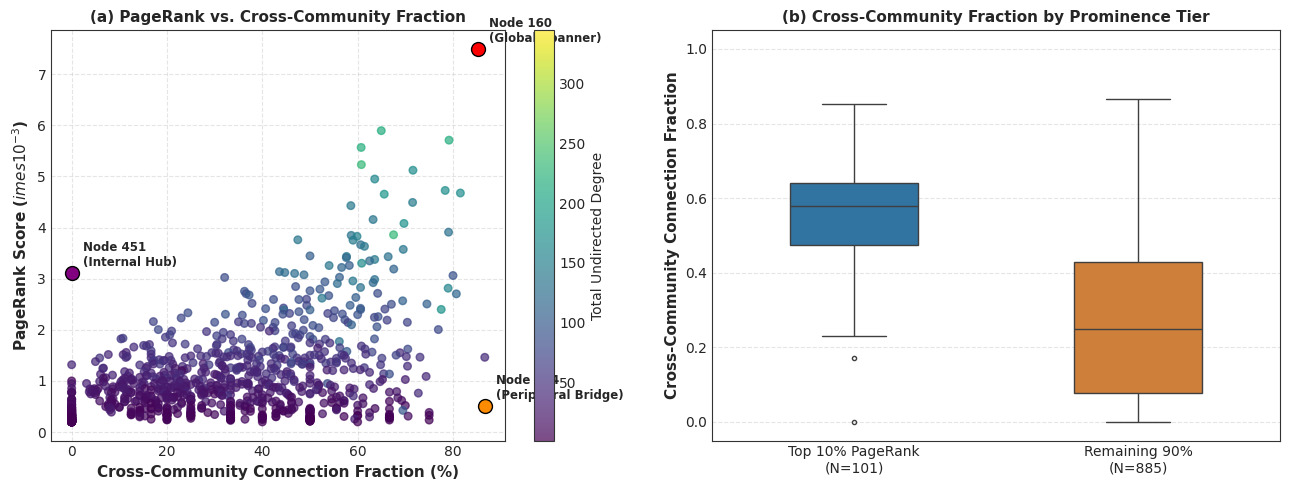

Descriptive Structural Archetypes Summary:


,Node ID,Department,Louvain Community,PageRank Score,PageRank Rank,Total Degree,Internal Edges,Cross Edges,Cross Fraction,External Comms Spanned
0,160,36,4,0.007495,1,345,51,294,85.22%,8
1,451,14,6,0.003117,37,13,13,0,0.00%,0
2,644,25,7,0.000514,633,15,2,13,86.67%,5


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Figure 5a: PageRank vs Cross-Community Fraction
scatter = axes[0].scatter(valid_eval["cross_community_fraction"] * 100, valid_eval["pagerank"] * 1000,
                          c=valid_eval["total_undirected_degree"], cmap="viridis", alpha=0.7, s=30)
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label("Total Undirected Degree", fontsize=10)

# Annotate case studies
cases = [(160, "red", "Node 160\n(Global Spanner)"), (451, "purple", "Node 451\n(Internal Hub)"), (644, "darkorange", "Node 644\n(Peripheral Bridge)")]
for nid, col, lbl in cases:
    r = valid_eval[valid_eval["node_id"] == nid].iloc[0]
    axes[0].scatter(r["cross_community_fraction"] * 100, r["pagerank"] * 1000, color=col, s=100, edgecolors="black", zorder=5)
    axes[0].annotate(lbl, (r["cross_community_fraction"] * 100, r["pagerank"] * 1000), textcoords="offset points", xytext=(8, 5), fontsize=8.5, weight="bold")

axes[0].set_xlabel("Cross-Community Connection Fraction (%)", fontsize=11, weight="bold")
axes[0].set_ylabel(r"PageRank Score ($	imes 10^{-3}$)", fontsize=11, weight="bold")
axes[0].set_title("(a) PageRank vs. Cross-Community Fraction", fontsize=11, weight="bold")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Figure 5b: Cross-Community Distributions
valid_eval["Tier"] = ["Top 10% PageRank\n(N=101)" if r <= 101 else "Remaining 90%\n(N=885)" for r in valid_eval["pagerank_rank_unique"]]
palette = {"Top 10% PageRank\n(N=101)": "#1f77b4", "Remaining 90%\n(N=885)": "#e67e22"}

sns.boxplot(data=valid_eval, x="Tier", y="cross_community_fraction", hue="Tier", palette=palette, ax=axes[1], width=0.45, fliersize=3, legend=False)
axes[1].set_ylabel("Cross-Community Connection Fraction", fontsize=11, weight="bold")
axes[1].set_xlabel("")
axes[1].set_title("(b) Cross-Community Fraction by Prominence Tier", fontsize=11, weight="bold")
axes[1].set_ylim(-0.05, 1.05)
axes[1].grid(True, axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Print Case Study Summary Table
print("Descriptive Structural Archetypes Summary:")
case_rows = []
for nid in [160, 451, 644]:
    r = valid_eval[valid_eval["node_id"] == nid].iloc[0]
    ext_comms = len(set(node_to_comm[v] for v in G_undir.neighbors(nid)) - {r["comm_id"]})
    case_rows.append({
        "Node ID": int(nid),
        "Department": int(r["department"]),
        "Louvain Community": int(r["comm_id"]),
        "PageRank Score": f"{r['pagerank']:.6f}",
        "PageRank Rank": int(r["pagerank_rank_unique"]),
        "Total Degree": int(r["total_undirected_degree"]),
        "Internal Edges": int(r["internal_edges_count"]),
        "Cross Edges": int(r["cross_community_count"]),
        "Cross Fraction": f"{r['cross_community_fraction']:.2%}",
        "External Comms Spanned": ext_comms,
    })
display(pd.DataFrame(case_rows))


## 8. Reproducibility Information & Software Manifest
We record all package versions, operating environment specifications, and dataset file hashes to ensure end-to-end auditability.


In [13]:
import platform
import sys

manifest = {
    "Python Version": sys.version.split()[0],
    "Operating System": platform.platform(),
    "NetworkX": nx.__version__,
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "SciPy": stats.__name__,
    "Random Seed": RANDOM_SEED,
    "Dataset": "SNAP Email-Eu-core",
    "G_raw Edges": G_raw.number_of_edges(),
    "G_analysis Edges": G_analysis.number_of_edges(),
    "G_undirected Edges": G_undir.number_of_edges(),
    "Louvain Communities (gamma=1.0)": len(sorted_comms),
    "Modularity Q": f"{mod_louvain:.4f}",
}

print("=== REPRODUCIBILITY MANIFEST ===")
for k, v in manifest.items():
    print(f"{k:32s}: {v}")


=== REPRODUCIBILITY MANIFEST ===
Python Version                  : 3.10.6
Operating System                : Windows-10-10.0.26300-SP0
NetworkX                        : 3.2.1
pandas                          : 2.1.4
NumPy                           : 1.26.4
SciPy                           : scipy.stats
Random Seed                     : 42
Dataset                         : SNAP Email-Eu-core
G_raw Edges                     : 25571
G_analysis Edges                : 24929
G_undirected Edges              : 16064
Louvain Communities (gamma=1.0) : 28
Modularity Q                    : 0.4131
